# Three DINOv3 detectors on SeaDronesSee

Group A - Paul Arnold


Written with Codex, run on Uppmax with H100

## What is compared?

| | Meta official | Lightly COCO-pretrained | SeaDronesSee-adapted |
|---|---|---|---|
| Backbone | Meta DINOv3 ViT-7B/16 | Meta DINOv3 ViT-S/16 | Same ViT-S/16 |
| Detector | Meta's COCO detector | Lightly LTDETR | Same LTDETR design, dataset-specific class head |
| Detector training | COCO, provided by Meta | COCO, provided by Lightly | Further fine-tuning on SeaDronesSee training split |
| SeaDronesSee training | None | None | Configured training steps |
| Quantization | None; BF16 inference | None; FP32 inference | None; FP32 inference |

All three use **the same validation images, 640 × 640 square inputs, shared person/boat
labels, confidence threshold, and COCO AP/AR settings**. Each implementation retains its
required normalization. In this dataset, swimmer maps to person and boat is retained;
other categories are excluded from shared evaluation. Ignore-region suppression is not implemented.

**Meta vs Lightly compares different detector systems**, including size, architecture,
pretraining, and numerical precision. **Lightly vs adapted compares domain adaptation**
with the same backbone and detector design; the output class head changes to SeaDronesSee classes.
Native SeaDronesSee metrics are shown for the adapted model separately.

These are validation results, with checkpoint selection on validation performance.
A 100-step run is a workflow experiment, not a converged benchmark or held-out test result.
Improvement/degradation examples are selected at the stated confidence and IoU thresholds;
they are qualitative illustrations, not a representative performance estimate.

Run in order on the remote GPU kernel. Execution outputs are stored in this notebook.
All plotted AP/AR metrics are calculated with the same pycocotools helper, rather than
comparing different frameworks' training-log metrics.

**Label scope:** the shared person ground truth contains SeaDronesSee's annotated swimmers.
COCO detections of real people on boats can count as false positives when they have no
swimmer annotation. Some error reductions therefore reflect the task's label scope.

Checkpoint sources: [Meta DINOv3 official detector](https://github.com/facebookresearch/dinov3#pretrained-heads---detector-trained-on-coco2017-dataset); [LightlyTrain COCO models](https://docs.lightly.ai/train/0.18.0/object_detection.html).


## Install once

Run only when creating the environment, then select the remote **DINOv3 comparison** kernel.

In [ ]:
import os
import subprocess
import sys
import tempfile
from pathlib import Path

environment = Path.cwd() / ".venv-dinov3-comparison"
with tempfile.TemporaryDirectory() as bootstrap:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--target", bootstrap,
                    "--ignore-installed", "--no-warn-script-location", "virtualenv"], check=True)
    subprocess.run([sys.executable, "-m", "virtualenv", "--quiet", str(environment)],
                   env={**os.environ, "PYTHONPATH": bootstrap}, check=True)
python = str(environment / "bin/python")
subprocess.run([python, "-m", "pip", "install", "--quiet", "torch==2.8.0", "torchvision==0.23.0",
                "--index-url", "https://download.pytorch.org/whl/cu126"], check=True)
subprocess.run([python, "-m", "pip", "install", "--quiet", "torch==2.8.0", "torchvision==0.23.0",
                "lightly-train==0.18.0", "pycocotools==2.0.11",
                "matplotlib", "pandas", "pillow", "tqdm", "omegaconf", "ftfy", "regex",
                "scikit-learn", "submitit", "termcolor", "ipykernel"], check=True)
subprocess.run([python, "-m", "ipykernel", "install", "--user", "--name", "dinov3-comparison",
                "--display-name", "DINOv3 comparison"], check=True, stdout=subprocess.DEVNULL)

## Imports and allocation

In [26]:
import os
os.environ["LIGHTLY_TRAIN_EVENTS_DISABLED"] = "1"

import copy
import gc
import io
import json
import random
import re
import sys
import time
import hashlib
import shutil
import tempfile
import urllib.request
import zipfile
from collections import defaultdict
from contextlib import redirect_stdout
from pathlib import Path

import lightly_train
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm
from torchvision.transforms import v2

if not torch.cuda.is_available():
    raise RuntimeError("Select the remote GPU kernel before continuing.")
DEVICE = "cuda:0"
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name} · {gpu.total_memory / 1024**3:.1f} GiB VRAM")
print(f"Python: {sys.executable}")
print(f"Working directory: {Path.cwd()}")

GPU: NVIDIA H100 NVL · 93.1 GiB VRAM
Python: /home/paulpaul/.venv-dinov3-comparison/bin/python
Working directory: /home/paulpaul


## Settings

`PROJECT` is the remote kernel's working directory. Set explicit dataset paths when needed.
The Meta loader uses existing official checkpoints and source; no quantization is applied.
Training benchmarks keep the effective batch at 32 and compare measured throughput.
New training intermediates use node-local temporary storage. The final inference checkpoint
and comparison outputs are copied/written to persistent `OUTPUT_ROOT`.

In [39]:
PROJECT = Path.cwd().resolve()  # Directory containing this notebook.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATA_ROOT = PROJECT / "data/SeaDronesSee_ODv2"
EXTRACTED = DATA_ROOT / "extracted"
ARCHIVE = DATA_ROOT / "dataset.zip"
DOWNLOAD_DATA = False
URL = ("https://cloud.cs.uni-tuebingen.de/index.php/s/ZZxX65FGnQ8zjBP"
       "/download?path=%2FCompressed%20Version")
TRAIN_JSON_INPUT = None  # Or Path("/path/to/instances_train.json").
VAL_JSON_INPUT = None
TRAIN_IMAGES_INPUT = None
VAL_IMAGES_INPUT = None

MODEL_NAME = "dinov3/vits16-ltdetr-coco"
IMAGE_SIZE = 640
TRAIN_STEPS = 100
BATCH_SIZE = 32  # Measured H100 default; remeasure after changing the allocation.
GRADIENT_ACCUMULATION = 1
NUM_WORKERS = 1
TRAIN_PRECISION = "bf16-mixed"
RUN_BENCHMARKS = False  # True reruns timing experiments; otherwise show saved measurements.
BENCHMARK_STEPS = 8
STAGE_TRAIN_IMAGES = True  # Copy original image bytes to local storage; do not resize.
META_BATCH_SIZE = 4
EXAMPLE_IOU = 0.5
EXAMPLES_PER_CHANGE = 2
MAX_EVAL_IMAGES = None  # Full validation. Set e.g. 32 for a workflow check.
EVAL_THRESHOLD = 0.001
DISPLAY_THRESHOLD = 0.3
RUN_NAME = "dinov3_vits16_comparison_001"
OUTPUT_ROOT = PROJECT / "runs" / RUN_NAME
TEMP_ROOT = Path(tempfile.gettempdir()) / f"dinov3-three-way-{os.environ.get('SLURM_JOB_ID', 'local')}"
TEMP_ROOT.mkdir(parents=True, exist_ok=True)
ADAPTED_RUN = TEMP_ROOT / "adapted_training_h100"
CHECKPOINT = OUTPUT_ROOT / "adapted_h100" / "exported_best.pt"
PREVIOUS_EVAL_DIR = OUTPUT_ROOT / "full_validation"
DINOV3_REPO = PROJECT / "third_party/dinov3"
BACKBONE_WEIGHTS = PROJECT / "weights/dinov3_vit7b16_pretrain_lvd1689m.pth"
DETECTOR_WEIGHTS = PROJECT / "weights/dinov3_vit7b16_coco2017_detr_head.pth"
META_LABEL = "Meta official · ViT-7B + detector"
META_TO_SHARED = {1: 1, 9: 2}  # Meta returns official COCO category IDs.
BASELINE_LABEL = "Lightly COCO · ViT-S/16 + LTDETR"
ADAPTED_LABEL = "SeaDronesSee-adapted · ViT-S/16 + LTDETR"

# Normalize names before matching; unknown dataset names cause an error.
SHARED_NAMES = {1: "person", 2: "boat"}
DATASET_TO_SHARED = {
    "swimmer": 1, "person": 1, "person_on_boat": 1, "person_in_water": 1,
    "boat": 2, "ignored": None,
    "jetski": None, "jet_ski": None, "buoy": None,
    "life_saving_appliances": None, "life_saving_appliance": None,
}
# Map baseline labels by model.classes names; its IDs need not be official COCO IDs.

## Optional dataset download

Existing datasets and Meta checkpoint files are reused. Lightly downloads its small model automatically.

In [28]:
def download(url, destination):
    """Download a file with a progress bar, overwriting its destination."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as response:
        with destination.open("wb") as output, tqdm(
            total=int(response.headers.get("Content-Length") or 0) or None,
            desc=destination.name, unit="B", unit_scale=True
        ) as progress:
            for chunk in iter(lambda: response.read(8 * 1024 * 1024), b""):
                output.write(chunk)
                progress.update(len(chunk))


if DOWNLOAD_DATA:
    download(URL, ARCHIVE)
    with zipfile.ZipFile(ARCHIVE) as archive:
        archive.extractall(EXTRACTED)
else:
    print("Using the existing extracted dataset:", EXTRACTED)

Using the existing extracted dataset: /home/paulpaul/data/SeaDronesSee_ODv2/extracted


## Dataset

Shared metrics map this dataset's swimmer category to person, retain boat, and exclude
jetski, life-saving appliances, buoy, and ignored categories. Native metrics retain all
five object classes except ignored. Spatial ignore-region suppression is not implemented.


In [29]:
def image_root(annotations):
    """Locate the extracted directory relative to the annotation filenames."""
    first = Path(annotations["images"][0]["file_name"])
    for match in EXTRACTED.rglob(first.name):
        root = match.parents[len(first.parts) - 1]
        if all((root / image["file_name"]).is_file() for image in annotations["images"]):
            return root


def load_split(split, annotation_path, images_path):
    """Load one labeled split, discovering paths when no explicit paths are configured."""
    annotation_path = Path(annotation_path) if annotation_path else next(
        EXTRACTED.rglob(f"instances_{split}.json"))
    annotations = json.loads(annotation_path.read_text())
    images_path = Path(images_path) if images_path else image_root(annotations)
    with redirect_stdout(io.StringIO()):
        coco = COCO(str(annotation_path))
    coco.dataset.setdefault("info", {})
    for ann in coco.anns.values():
        ann.setdefault("iscrowd", 0)
        ann.setdefault("area", ann["bbox"][2] * ann["bbox"][3])
    return annotation_path, images_path, coco


TRAIN_JSON, TRAIN_IMAGES, train_gt = load_split("train", TRAIN_JSON_INPUT, TRAIN_IMAGES_INPUT)
VAL_JSON, VAL_IMAGES, val_gt = load_split("val", VAL_JSON_INPUT, VAL_IMAGES_INPUT)
class_names = {cid: category["name"] for cid, category in train_gt.cats.items()}
all_val_ids = sorted(val_gt.getImgIds())
if MAX_EVAL_IMAGES is not None and MAX_EVAL_IMAGES < 1:
    raise ValueError("MAX_EVAL_IMAGES must be positive or None.")
eval_ids = all_val_ids if MAX_EVAL_IMAGES is None else sorted(
    random.Random(SEED).sample(all_val_ids, min(MAX_EVAL_IMAGES, len(all_val_ids))))
SCOPE = "Full validation" if len(eval_ids) == len(all_val_ids) else "Validation subset"


def normalize_name(name):
    """Normalize dataset labels for the configured shared-class mapping."""
    return re.sub(r"[\s-]+", "_", name.strip().lower())


ignored_ids = [cid for cid, name in class_names.items() if normalize_name(name) == "ignored"]
native_to_shared = {cid: DATASET_TO_SHARED[normalize_name(name)]
                    for cid, name in class_names.items()}


def mapped_ground_truth(mapping, names):
    """Copy validation annotations into a chosen class vocabulary, keeping all images."""
    ground_truth = COCO()
    ground_truth.dataset = copy.deepcopy(val_gt.dataset)
    ground_truth.dataset["categories"] = [{"id": cid, "name": name} for cid, name in names.items()]
    ground_truth.dataset["annotations"] = [
        ann for ann in ground_truth.dataset["annotations"]
        if mapping.get(ann["category_id"]) is not None
    ]
    for ann in ground_truth.dataset["annotations"]:
        ann["category_id"] = mapping[ann["category_id"]]
    with redirect_stdout(io.StringIO()):
        ground_truth.createIndex()
    return ground_truth


shared_gt = mapped_ground_truth(native_to_shared, SHARED_NAMES)
native_names = {cid: name for cid, name in class_names.items() if cid not in ignored_ids}
native_gt = mapped_ground_truth({cid: cid for cid in native_names}, native_names)
print(f"{SCOPE}: {len(eval_ids)} / {len(all_val_ids)} images")
print("Train images:", TRAIN_IMAGES)
print("Validation images:", VAL_IMAGES)

Full validation: 1547 / 1547 images
Train images: /home/paulpaul/data/SeaDronesSee_ODv2/extracted/Compressed Version/images/train
Validation images: /home/paulpaul/data/SeaDronesSee_ODv2/extracted/Compressed Version/images/val


## Prediction, caching, and evaluation helpers

In [30]:
EVAL_DIR = OUTPUT_ROOT / ("three_way_full_validation" if len(eval_ids) == len(all_val_ids) else "three_way_validation_subset")
EVAL_DIR.mkdir(parents=True, exist_ok=True)
METRIC_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large",
                "AR@1", "AR@10", "AR@100", "AR_small", "AR_medium", "AR_large"]


def collect_predictions(predict_image, label_mapping, label):
    """Predict selected images and convert original-pixel xyxy boxes to COCO xywh."""
    predictions = []
    for image_id in tqdm(eval_ids, desc=label):
        with Image.open(VAL_IMAGES / val_gt.imgs[image_id]["file_name"]) as image:
            result = predict_image(image.convert("RGB"))
        boxes = result["boxes"].detach().float().cpu().tolist()
        scores = result["scores"].detach().float().cpu().tolist()
        labels = result["labels"].detach().cpu().tolist()
        for (x1, y1, x2, y2), score, label_id in zip(boxes, scores, labels):
            category = label_mapping.get(int(label_id))
            if category is not None and score >= EVAL_THRESHOLD:
                predictions.append({"image_id": image_id, "category_id": category,
                                    "bbox": [x1, y1, x2-x1, y2-y1], "score": score})
    return predictions


def evaluate_coco(ground_truth, predictions, destination):
    """Compute standard COCO metrics and per-class AP, including empty predictions."""
    with redirect_stdout(io.StringIO()):
        if predictions:
            detected = ground_truth.loadRes(copy.deepcopy(predictions))
        else:
            detected = COCO()
            detected.dataset = {"images": ground_truth.dataset["images"],
                                "categories": ground_truth.dataset["categories"], "annotations": []}
            detected.createIndex()
        evaluator = COCOeval(ground_truth, detected, "bbox")
        evaluator.params.imgIds = eval_ids
        evaluator.params.catIds = sorted(ground_truth.cats)
        evaluator.params.maxDets = [1, 10, 100]
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    metrics = pd.Series(evaluator.stats, index=METRIC_NAMES).replace(-1, np.nan)
    per_class = {}
    for index, cid in enumerate(evaluator.params.catIds):
        precision = evaluator.eval["precision"][:, :, index, 0, -1]
        valid = precision[precision >= 0]
        per_class[ground_truth.cats[cid]["name"]] = valid.mean() if valid.size else np.nan
    per_class = pd.Series(per_class, name="AP")
    destination.mkdir(parents=True, exist_ok=True)
    (destination / "predictions.json").write_text(json.dumps(predictions))
    metrics.to_csv(destination / "metrics.csv", header=["value"])
    per_class.to_csv(destination / "per_class_ap.csv")
    # Keep small curve arrays, not COCO's large prediction/matching object graph.
    result = {"metrics": metrics, "per_class": per_class,
              "precision": evaluator.eval["precision"].copy(),
              "recall_thresholds": evaluator.params.recThrs.copy(),
              "iou_thresholds": evaluator.params.iouThrs.copy(),
              "category_ids": list(evaluator.params.catIds)}
    del detected, evaluator
    gc.collect()
    return result

def predict_ltdetr(model, image):
    """Predict square inputs and return xyxy boxes in original-image pixels.

    Both checkpoints use this preprocessing, confidence threshold, and output
    conversion. LightlyTrain returns boxes in the resized input's pixel coordinates.
    """
    width, height = image.size
    resized = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    with torch.inference_mode():
        result = model.predict(resized, threshold=EVAL_THRESHOLD)
    scale = torch.tensor([
        width / IMAGE_SIZE, height / IMAGE_SIZE,
        width / IMAGE_SIZE, height / IMAGE_SIZE,
    ])
    boxes = result["bboxes"].detach().float().cpu() * scale
    return {"boxes": boxes, "scores": result["scores"], "labels": result["labels"]}

def cache_signature(model):
    """Identify the model, data, image scope, threshold, and input resolution."""
    return {"model": model, "val_sha256": hashlib.sha256(VAL_JSON.read_bytes()).hexdigest(),
            "image_ids": eval_ids, "image_size": IMAGE_SIZE, "threshold": EVAL_THRESHOLD}


def read_cached_predictions(directory, signature):
    """Reuse predictions only when their manifest matches the evaluation settings."""
    manifest = directory / "manifest.json"
    predictions = directory / "predictions.json"
    if manifest.is_file() and predictions.is_file() and json.loads(manifest.read_text()) == signature:
        print("Reusing predictions:", predictions)
        return json.loads(predictions.read_text())
    return None


def write_prediction_manifest(directory, signature):
    """Record prediction provenance after successful inference and export."""
    (directory / "manifest.json").write_text(json.dumps(signature, indent=2))


def save_predictions(directory, predictions):
    """Save predictions immediately so evaluation can be rerun without GPU inference."""
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "predictions.json").write_text(json.dumps(predictions))

## Meta official detector: ViT-7B + COCO detector

The architecture is constructed on CUDA, then official backbone/head checkpoints are
memory-mapped and copied into it. This avoids a full CPU model/checkpoint copy in the
11.7 GiB host allocation. BF16 is a floating-point format, not INT8 quantization.
Missing parameter aliases are accepted only if the same underlying parameter was loaded.

In [31]:
def load_meta_detector():
    """Load Meta's unmodified architecture and official weights without a large RAM copy."""
    for path in (DINOV3_REPO / "hubconf.py", BACKBONE_WEIGHTS, DETECTOR_WEIGHTS):
        if not path.is_file():
            raise FileNotFoundError(path)
    previous_dtype = torch.get_default_dtype()
    try:
        torch.set_default_dtype(torch.bfloat16)
        with torch.device(DEVICE):
            model = torch.hub.load(str(DINOV3_REPO), "dinov3_vit7b16_de",
                                   source="local", pretrained=False)
    finally:
        torch.set_default_dtype(previous_dtype)
    backbone = next(module for module in model.modules()
                    if hasattr(module, "get_intermediate_layers") and hasattr(module, "blocks"))
    state = torch.load(BACKBONE_WEIGHTS, map_location="cpu", mmap=True, weights_only=True)
    backbone.load_state_dict(state, strict=True)
    del state
    state = torch.load(DETECTOR_WEIGHTS, map_location="cpu", mmap=True, weights_only=True)["model"]
    incompatible = model.detector.load_state_dict(state, strict=False)
    prefix = next(name for name, module in model.detector.named_modules() if module is backbone) + "."
    parameters = dict(model.detector.named_parameters(remove_duplicate=False))
    loaded_ids = {id(parameters[key]) for key in state if key in parameters}
    missing = [key for key in incompatible.missing_keys if not key.startswith(prefix)
               and key in parameters and id(parameters[key]) not in loaded_ids]
    if missing or incompatible.unexpected_keys:
        raise RuntimeError(f"Checkpoint mismatch: missing={missing}, unexpected={incompatible.unexpected_keys}")
    del state, backbone, parameters
    gc.collect()
    return model.to(DEVICE).eval().requires_grad_(False)


meta_transform = v2.Compose([
    v2.ToImage(), v2.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])
meta_signature = cache_signature("Meta dinov3_vit7b16_de; official checkpoints; BF16")
meta_predictions = read_cached_predictions(EVAL_DIR / "meta/shared", meta_signature)
if meta_predictions is None:
    meta_model = load_meta_detector()
    meta_predictions = []
    started = time.perf_counter()
    for start in tqdm(range(0, len(eval_ids), META_BATCH_SIZE), desc="Meta official"):
        batch_ids = eval_ids[start:start + META_BATCH_SIZE]
        tensors, sizes = [], []
        for image_id in batch_ids:
            with Image.open(VAL_IMAGES / val_gt.imgs[image_id]["file_name"]) as image:
                image = image.convert("RGB")
                sizes.append(image.size)
                tensors.append(meta_transform(image).to(device=DEVICE, dtype=torch.bfloat16))
        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
            results = meta_model(tensors)
        for image_id, (width, height), result in zip(batch_ids, sizes, results):
            boxes = result["boxes"].detach().float().cpu() * torch.tensor(
                [width / IMAGE_SIZE, height / IMAGE_SIZE, width / IMAGE_SIZE, height / IMAGE_SIZE])
            scores = result["scores"].detach().float().cpu()
            labels = result["labels"].detach().cpu()
            if not torch.isfinite(boxes).all() or not torch.isfinite(scores).all():
                raise RuntimeError(f"Non-finite Meta predictions for image {image_id}")
            for (x1, y1, x2, y2), score, label in zip(boxes.tolist(), scores.tolist(), labels.tolist()):
                category = META_TO_SHARED.get(int(label))
                if category is not None and score >= EVAL_THRESHOLD:
                    meta_predictions.append({"image_id": image_id, "category_id": category,
                                             "bbox": [x1, y1, x2-x1, y2-y1], "score": score})
    torch.cuda.synchronize()
    print(f"Meta inference: {time.perf_counter() - started:.1f}s for {len(eval_ids)} images")
    del meta_model, results, tensors
    gc.collect()
    torch.cuda.empty_cache()
    save_predictions(EVAL_DIR / "meta/shared", meta_predictions)
    write_prediction_manifest(EVAL_DIR / "meta/shared", meta_signature)
meta_result = evaluate_coco(shared_gt, meta_predictions, EVAL_DIR / "meta/shared")
display(meta_result["metrics"].to_frame(META_LABEL).round(4))

Meta official: 100%|█████████████████████████████████████████████████████████████████| 387/387 [04:44<00:00,  1.36it/s]


Meta inference: 286.2s for 1547 images


,Meta official · ViT-7B + detector
AP,0.4125
AP50,0.7685
AP75,0.4028
AP_small,0.2574
AP_medium,0.3397
AP_large,0.5035
AR@1,0.1828
AR@10,0.5145
AR@100,0.5935
AR_small,0.4099


## Lightly COCO-pretrained detector: ViT-S/16 + LTDETR

In [32]:
baseline_signature = cache_signature(MODEL_NAME + "; COCO-pretrained; FP32")
baseline_predictions = read_cached_predictions(EVAL_DIR / "baseline/shared", baseline_signature)
previous_report_path = PREVIOUS_EVAL_DIR / "report.json"
if baseline_predictions is None and previous_report_path.is_file():
    previous_report = json.loads(previous_report_path.read_text())
    if (previous_report.get("baseline") == MODEL_NAME and previous_report.get("image_ids") == eval_ids
            and previous_report.get("image_size") == IMAGE_SIZE
            and previous_report.get("evaluation_threshold") == EVAL_THRESHOLD
            and previous_report.get("val_annotations") == str(VAL_JSON)):
        previous_predictions = PREVIOUS_EVAL_DIR / "baseline/shared/predictions.json"
        if previous_predictions.is_file():
            baseline_predictions = json.loads(previous_predictions.read_text())
            print("Reusing the previously verified full-validation Lightly baseline.")
if baseline_predictions is None:
    baseline_model = lightly_train.load_model(MODEL_NAME, device=DEVICE).eval()
    shared_name_to_id = {name: cid for cid, name in SHARED_NAMES.items()}
    baseline_label_to_shared = {int(label): shared_name_to_id[normalize_name(name)]
                               for label, name in baseline_model.classes.items()
                               if normalize_name(name) in shared_name_to_id}
    if set(baseline_label_to_shared.values()) != set(SHARED_NAMES):
        raise ValueError("The baseline checkpoint must contain person and boat classes.")

    def predict_baseline(image):
        """Predict with Lightly's COCO checkpoint before SeaDronesSee adaptation."""
        return predict_ltdetr(baseline_model, image)

    baseline_predictions = collect_predictions(predict_baseline, baseline_label_to_shared, "Lightly COCO")
    del baseline_model
    gc.collect()
    torch.cuda.empty_cache()
baseline_result = evaluate_coco(shared_gt, baseline_predictions, EVAL_DIR / "baseline/shared")
write_prediction_manifest(EVAL_DIR / "baseline/shared", baseline_signature)
display(baseline_result["metrics"].to_frame(BASELINE_LABEL).round(4))

Reusing the previously verified full-validation Lightly baseline.


,Lightly COCO · ViT-S/16 + LTDETR
AP,0.3562
AP50,0.6786
AP75,0.3326
AP_small,0.1814
AP_medium,0.2231
AP_large,0.4421
AR@1,0.1671
AR@10,0.5084
AR@100,0.5603
AR_small,0.3901


## Measure H100 training throughput

All candidates use effective batch size 32, the same training split, seed, and image size.
Short timing runs use only a small validation subset to avoid timing full evaluation repeatedly.
The benchmark reports training time separately from setup/validation. It measures throughput,
not accuracy. The fastest successful configuration is used for the full adaptation run.
Original image bytes may be staged to node-local storage; image resolution is not changed.
The measured H100 defaults are batch 32, accumulation 1, one worker, and BF16. Saved timing
measurements are displayed by default; set `RUN_BENCHMARKS=True` to remeasure after changing
the GPU/CPU allocation. One-time image staging is reported separately from training speed.


Stage original training images: 100%|███████████████████████████████████████████| 8930/8930 [00:00<00:00, 46176.37it/s]


Original image bytes staged locally in 0.2s; no resizing or recompression.
Displaying saved H100 timing measurements; set RUN_BENCHMARKS=True to remeasure.


,name,batch_size,accumulation,workers,precision,seconds_per_step,images_per_second,data_seconds,gpu_util_percent,gpu_peak_mb,status,total_seconds
0,Previous batching,8,4,0,16-mixed,2.49,12.851,1.95,20.8,25577.7,ok,22.906
1,Larger BF16 microbatch,32,1,0,bf16-mixed,2.34,13.675,1.93,17.4,56897.1,ok,21.608
2,Larger BF16 + one worker,32,1,1,bf16-mixed,2.11,15.166,1.58,17.1,50319.1,ok,20.820


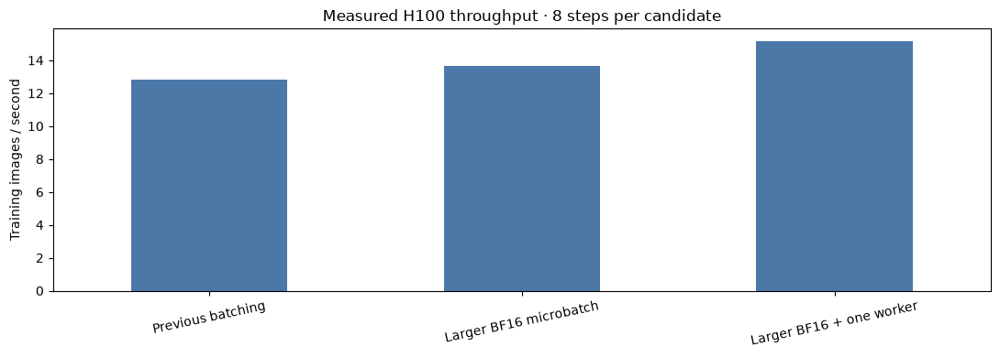

Selected training settings: 32 × 1 workers: 1 precision: bf16-mixed


In [40]:
def training_data(validation_json=VAL_JSON):
    """Return the same COCO training data, with an optional timing-only validation subset."""
    return {"format": "coco", "ignore_classes": ignored_ids,
            "train": {"annotations": str(TRAIN_JSON), "images": str(training_images)},
            "val": {"annotations": str(validation_json), "images": str(VAL_IMAGES)}}


def loader_settings(workers):
    """Bound prefetch memory when a separate data worker is enabled."""
    return {"prefetch_factor": 1, "persistent_workers": False} if workers else {}


def read_training_profile(directory):
    """Read the measured training-step time, GPU use, and memory from Lightly's log."""
    text = (directory / "train.log").read_text()
    text = re.sub(r"\x1b\[[0-9;]*m", "", text)
    rows = re.findall(r"Train Step\s+\d+/\d+.*?GPU Util\s+([\d.]+)%.*?GPU Max Mem\s+([\d.]+) MB.*?Step Time\s+([\d.]+)s.*?Data Time\s+([\d.]+)s", text)
    if not rows:
        raise RuntimeError(f"No measured training profile found: {directory}")
    gpu_use, memory_mb, seconds, data_seconds = map(float, rows[-1])
    return {"seconds_per_step": seconds, "images_per_second": 32 / seconds,
            "data_seconds": data_seconds, "gpu_util_percent": gpu_use,
            "gpu_peak_mb": memory_mb}


training_images = TRAIN_IMAGES
staging_seconds = 0.0
if STAGE_TRAIN_IMAGES:
    training_images = TEMP_ROOT / "train_images"
    staging_started = time.perf_counter()
    for image in tqdm(train_gt.dataset["images"], desc="Stage original training images"):
        source = TRAIN_IMAGES / image["file_name"]
        destination = training_images / image["file_name"]
        if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, destination)
    staging_seconds = time.perf_counter() - staging_started
    print(f"Original image bytes staged locally in {staging_seconds:.1f}s; no resizing or recompression.")

# Two allocated CPU cores cannot feed an H100 as a large CPU allocation can.
# Limit PyTorch/OpenCV CPU pools to avoid oversubscription with a data worker.
torch.set_num_threads(min(2, len(os.sched_getaffinity(0))))
import cv2
cv2.setNumThreads(1)
torch.set_float32_matmul_precision("high")

benchmark_rows = []
if RUN_BENCHMARKS:
    subset_ids = set(all_val_ids[:32])
    subset = {**val_gt.dataset,
              "images": [image for image in val_gt.dataset["images"] if image["id"] in subset_ids],
              "annotations": [ann for ann in val_gt.dataset["annotations"] if ann["image_id"] in subset_ids]}
    subset_json = TEMP_ROOT / "benchmark_val_32.json"
    subset_json.write_text(json.dumps(subset))
    candidates = [
        {"name": "Previous batching", "batch_size": 8, "accumulation": 4, "workers": 0, "precision": "16-mixed"},
        {"name": "Larger BF16 microbatch", "batch_size": 32, "accumulation": 1, "workers": 0, "precision": "bf16-mixed"},
        {"name": "Larger BF16 + one worker", "batch_size": 32, "accumulation": 1, "workers": 1, "precision": "bf16-mixed"},
    ]
    for index, candidate in enumerate(candidates):
        print("Measuring:", candidate)
        directory = TEMP_ROOT / f"benchmark_{index}"
        started = time.perf_counter()
        try:
            lightly_train.train_object_detection(
                out=str(directory), model=MODEL_NAME, data=training_data(subset_json),
                steps=BENCHMARK_STEPS, batch_size=candidate["batch_size"],
                gradient_accumulation_steps=candidate["accumulation"],
                accelerator="gpu", devices=1, precision=candidate["precision"],
                num_workers=candidate["workers"], loader_args=loader_settings(candidate["workers"]), seed=SEED,
                transform_args={"image_size": (IMAGE_SIZE, IMAGE_SIZE)},
                logger_args={"log_every_num_steps": 1, "val_every_num_steps": BENCHMARK_STEPS, "tensorboard": None},
                save_checkpoint_args={"save_best": False, "save_last": False},
                checkpoint=None, resume_interrupted=False, overwrite=True,
            )
            row = {**candidate, **read_training_profile(directory), "status": "ok",
                   "total_seconds": time.perf_counter() - started}
        except torch.cuda.OutOfMemoryError as error:
            row = {**candidate, "status": "GPU out of memory", "error": str(error)}
        benchmark_rows.append(row)
        gc.collect()
        torch.cuda.empty_cache()
elif (EVAL_DIR / "h100_training_benchmark.csv").is_file():
    benchmark_rows = pd.read_csv(EVAL_DIR / "h100_training_benchmark.csv").to_dict("records")
    print("Displaying saved H100 timing measurements; set RUN_BENCHMARKS=True to remeasure.")

if benchmark_rows:
    benchmark = pd.DataFrame(benchmark_rows)
    successful = benchmark.loc[benchmark["status"] == "ok"]
    if successful.empty:
        raise RuntimeError("No training configuration completed the throughput measurement.")
    selected = successful.loc[successful["seconds_per_step"].idxmin()]
    BATCH_SIZE = int(selected["batch_size"])
    GRADIENT_ACCUMULATION = int(selected["accumulation"])
    NUM_WORKERS = int(selected["workers"])
    TRAIN_PRECISION = str(selected["precision"])
    benchmark.to_csv(EVAL_DIR / "h100_training_benchmark.csv", index=False)
    display(benchmark.round(3))
    fig, ax = plt.subplots(figsize=(11, 4))
    successful.plot.bar(x="name", y="images_per_second", ax=ax, rot=12, legend=False, color="#4c78a8")
    ax.set(ylabel="Training images / second", xlabel="", title=f"Measured H100 throughput · {BENCHMARK_STEPS} steps per candidate")
    fig.tight_layout()
    fig.savefig(EVAL_DIR / "h100_training_throughput.png", dpi=160)
    plt.show()
print("Selected training settings:", BATCH_SIZE, "×", GRADIENT_ACCUMULATION,
      "workers:", NUM_WORKERS, "precision:", TRAIN_PRECISION)


## Train the SeaDronesSee-adapted detector

Start from Lightly's COCO-pretrained checkpoint. Keep the same effective batch of 32.
Save only the best checkpoint, and copy its inference export to persistent storage.
The temporary training directory may be removed by the node after the allocation ends.

In [38]:
training_started = time.perf_counter()
lightly_train.train_object_detection(
    out=str(ADAPTED_RUN), model=MODEL_NAME, data=training_data(),
    steps=TRAIN_STEPS, batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    accelerator="gpu", devices=1, precision=TRAIN_PRECISION,
    num_workers=NUM_WORKERS, loader_args=loader_settings(NUM_WORKERS), seed=SEED,
    transform_args={"image_size": (IMAGE_SIZE, IMAGE_SIZE)},
    logger_args={"val_every_num_steps": min(100, TRAIN_STEPS), "tensorboard": None},
    save_checkpoint_args={"save_every_num_steps": min(100, TRAIN_STEPS), "save_best": True, "save_last": False},
    checkpoint=None, resume_interrupted=False, overwrite=True,
)
training_wall_seconds = time.perf_counter() - training_started
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(ADAPTED_RUN / "exported_models/exported_best.pt", CHECKPOINT)
training_profile = read_training_profile(ADAPTED_RUN)
training_profile["total_seconds_including_validation"] = training_wall_seconds
training_profile["staging_seconds"] = staging_seconds
training_profile["previous_full_run_seconds_per_step"] = 2.56
training_profile["speedup_vs_previous_full_run"] = 2.56 / training_profile["seconds_per_step"]
(EVAL_DIR / "training_profile.json").write_text(json.dumps(training_profile, indent=2))
display(pd.Series(training_profile, name="Measured training profile").to_frame().round(3))
print("Persistent inference checkpoint:", CHECKPOINT)
gc.collect()
torch.cuda.empty_cache()


Using bfloat16 Automatic Mixed Precision (AMP)
Args: {
    "accelerator": "gpu",
    "batch_size": 32,
    "checkpoint": null,
    "data": {
        "format": "coco",
        "ignore_classes": [
            0
        ],
        "skip_if_annotations_missing": false,
        "train": {
            "annotations": "/home/paulpaul/data/SeaDronesSee_ODv2/extracted/Compressed Version/annotations/instances_train.json",
            "images": "/tmp/dinov3-three-way-7840736/train_images"
        },
        "val": {
            "annotations": "/home/paulpaul/data/SeaDronesSee_ODv2/extracted/Compressed Version/annotations/instances_val.json",
            "images": "/home/paulpaul/data/SeaDronesSee_ODv2/extracted/Compressed Version/images/val"
        }
    },
    "debug_args": null,
    "devices": 1,
    "float32_matmul_precision": "auto",
    "gradient_accumulation_steps": 1,
    "loader_args": {
        "persistent_workers": false,
        "prefetch_factor": 1
    },
    "logger_args": {
        

,Measured training profile
seconds_per_step,2.130
images_per_second,15.023
data_seconds,1.720
gpu_util_percent,21.800
gpu_peak_mb,50806.200
total_seconds_including_validation,286.116
staging_seconds,28.178
previous_full_run_seconds_per_step,2.560
speedup_vs_previous_full_run,1.202


Persistent inference checkpoint: /home/paulpaul/runs/dinov3_vits16_comparison_001/adapted_h100/exported_best.pt


## Evaluate the adapted checkpoint on the same validation images

In [41]:
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Run the adaptation training cell first: {CHECKPOINT}")
adapted_model = lightly_train.load_model(str(CHECKPOINT), device=DEVICE).eval()
name_to_native = {name: cid for cid, name in native_names.items()}
adapted_label_to_native = {int(label): name_to_native[name]
                           for label, name in adapted_model.classes.items()}


def predict_adapted(image):
    """Predict with the adapted checkpoint using the baseline's preprocessing."""
    return predict_ltdetr(adapted_model, image)

adapted_native_predictions = collect_predictions(predict_adapted, adapted_label_to_native, "Adapted")
del adapted_model
gc.collect()
torch.cuda.empty_cache()
adapted_shared_predictions = [
    {**prediction, "category_id": native_to_shared[prediction["category_id"]]}
    for prediction in adapted_native_predictions
    if native_to_shared[prediction["category_id"]] is not None
]
adapted_shared_result = evaluate_coco(shared_gt, adapted_shared_predictions, EVAL_DIR / "adapted/shared")
adapted_native_result = evaluate_coco(native_gt, adapted_native_predictions, EVAL_DIR / "adapted/native")
display(adapted_shared_result["metrics"].to_frame(ADAPTED_LABEL).round(4))

Adapted: 100%|█████████████████████████████████████████████████████████████████████| 1547/1547 [01:41<00:00, 15.30it/s]


,SeaDronesSee-adapted · ViT-S/16 + LTDETR
AP,0.4522
AP50,0.8213
AP75,0.4370
AP_small,0.2953
AP_medium,0.4086
AP_large,0.5435
AR@1,0.1950
AR@10,0.5368
AR@100,0.5801
AR_small,0.3891


## Three-way shared person/boat comparison

The three model columns use the same validation scope. AP/AR values range from 0 to 1.
Pairwise differences are reported separately in percentage points. Precision–recall curves use consistent model colors; example boxes encode TP/FP/FN.

,Meta official · ViT-7B + detector,Lightly COCO · ViT-S/16 + LTDETR,SeaDronesSee-adapted · ViT-S/16 + LTDETR
AP,0.4125,0.3562,0.4522
AP50,0.7685,0.6786,0.8213
AP75,0.4028,0.3326,0.4370
AP_small,0.2574,0.1814,0.2953
AP_medium,0.3397,0.2231,0.4086
AP_large,0.5035,0.4421,0.5435
AR@1,0.1828,0.1671,0.1950
AR@10,0.5145,0.5084,0.5368
AR@100,0.5935,0.5603,0.5801
AR_small,0.4099,0.3901,0.3891


,Meta official · ViT-7B + detector,Lightly COCO · ViT-S/16 + LTDETR,SeaDronesSee-adapted · ViT-S/16 + LTDETR
person,0.2567,0.2109,0.2827
boat,0.5684,0.5014,0.6217


,Lightly − Meta (pp),Adapted − Lightly (pp),Adapted − Meta (pp)
AP,-5.64,9.61,3.97
AP50,-8.99,14.27,5.28
AP75,-7.02,10.44,3.42
AP_small,-7.59,11.39,3.80
AP_medium,-11.66,18.55,6.89
AP_large,-6.14,10.14,4.00
AR@1,-1.57,2.78,1.21
AR@10,-0.61,2.84,2.23
AR@100,-3.32,1.97,-1.34
AR_small,-1.98,-0.10,-2.08


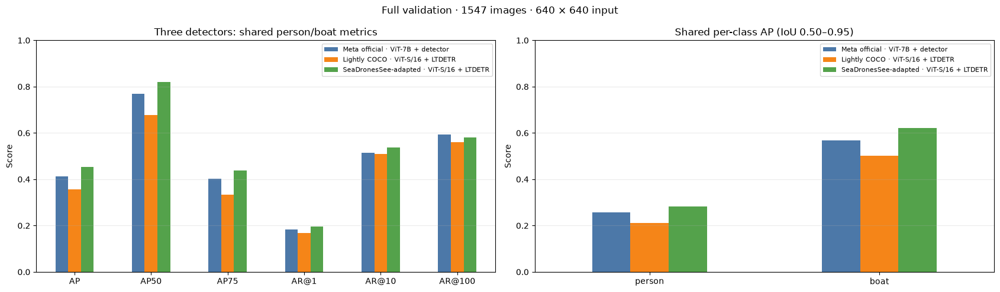

In [42]:
model_results = {META_LABEL: meta_result, BASELINE_LABEL: baseline_result,
                 ADAPTED_LABEL: adapted_shared_result}
model_predictions = {META_LABEL: meta_predictions, BASELINE_LABEL: baseline_predictions,
                     ADAPTED_LABEL: adapted_shared_predictions}
MODEL_COLORS = {META_LABEL: "#4c78a8", BASELINE_LABEL: "#f58518", ADAPTED_LABEL: "#54a24b"}
comparison = pd.DataFrame({name: result["metrics"] for name, result in model_results.items()})
per_class_comparison = pd.DataFrame({name: result["per_class"] for name, result in model_results.items()})
differences = pd.DataFrame({
    "Lightly − Meta (pp)": (comparison[BASELINE_LABEL] - comparison[META_LABEL]) * 100,
    "Adapted − Lightly (pp)": (comparison[ADAPTED_LABEL] - comparison[BASELINE_LABEL]) * 100,
    "Adapted − Meta (pp)": (comparison[ADAPTED_LABEL] - comparison[META_LABEL]) * 100,
})
for filename, frame in (("shared_comparison.csv", comparison), ("shared_per_class_comparison.csv", per_class_comparison),
                        ("shared_pairwise_differences.csv", differences)):
    frame.to_csv(EVAL_DIR / filename)
display(comparison.round(4))
display(per_class_comparison.round(4))
display(differences.round(2))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
comparison.loc[["AP", "AP50", "AP75", "AR@1", "AR@10", "AR@100"]].plot.bar(
    ax=axes[0], rot=0, color=list(MODEL_COLORS.values()))
per_class_comparison.plot.bar(ax=axes[1], rot=0, color=list(MODEL_COLORS.values()))
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_title("Three detectors: shared person/boat metrics")
axes[1].set_title("Shared per-class AP (IoU 0.50–0.95)")
fig.suptitle(f"{SCOPE} · {len(eval_ids)} images · {IMAGE_SIZE} × {IMAGE_SIZE} input")
fig.tight_layout()
fig.savefig(EVAL_DIR / "three_way_comparison.png", dpi=160)
plt.show()

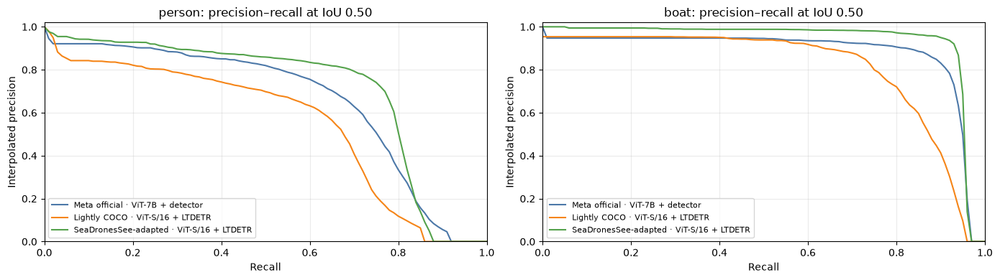

In [43]:
fig, axes = plt.subplots(1, len(SHARED_NAMES), figsize=(14, 4), squeeze=False)
for ax, (cid, name) in zip(axes[0], SHARED_NAMES.items()):
    for label, result in model_results.items():
        category_index = result["category_ids"].index(cid)
        iou_index = int(np.flatnonzero(np.isclose(result["iou_thresholds"], 0.5))[0])
        precision = result["precision"][iou_index, :, category_index, 0, -1]
        valid = precision >= 0
        ax.plot(result["recall_thresholds"][valid], precision[valid], label=label, color=MODEL_COLORS[label])
    ax.set(title=f"{name}: precision–recall at IoU 0.50", xlabel="Recall", ylabel="Interpolated precision",
           xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(EVAL_DIR / "three_way_precision_recall.png", dpi=160)
plt.show()

## Find improvements and degradations

Use class-aware, score-ordered one-to-one matching at `EXAMPLE_IOU` and `DISPLAY_THRESHOLD`.
For each image, errors = missed ground-truth boxes + false-positive predictions.
Rank changes in this count for Meta → Lightly, Lightly → adapted, and Meta → adapted.
The same examples show **ground truth plus all three models**, with TP/FP/FN counts.
These selected cases depend on thresholds and can include annotation or ignore-region limitations.
Each selected view uses the same crop in all four columns, centered on a newly detected/missed
object or a changed false positive. TP/FP/FN counts in panel titles refer to the full image.

Among readable scenes, examples with gained/lost true-positive matches are preferred over
FP-only changes, so the panels emphasize actual gains/losses on annotated target objects.


In [44]:
def group_predictions(predictions):
    """Group predictions by image for thresholded qualitative comparisons."""
    grouped = defaultdict(list)
    for prediction in predictions:
        if prediction["score"] >= DISPLAY_THRESHOLD:
            grouped[prediction["image_id"]].append(prediction)
    return grouped


def box_iou(box, boxes):
    """Compute IoU between one COCO xywh box and a list of COCO xywh boxes."""
    if not boxes:
        return np.empty(0)
    x, y, width, height = box
    array = np.asarray(boxes, dtype=float)
    intersection_width = np.maximum(0, np.minimum(x + width, array[:, 0] + array[:, 2]) - np.maximum(x, array[:, 0]))
    intersection_height = np.maximum(0, np.minimum(y + height, array[:, 1] + array[:, 3]) - np.maximum(y, array[:, 1]))
    intersection = intersection_width * intersection_height
    union = width * height + array[:, 2] * array[:, 3] - intersection
    return intersection / np.maximum(union, 1e-12)


def match_detections(annotations, predictions):
    """Match same-class detections greedily by score at the selected IoU threshold."""
    matched = set()
    true_positives, false_positives = [], []
    for prediction in sorted(predictions, key=lambda item: item["score"], reverse=True):
        candidates = [i for i, ann in enumerate(annotations)
                      if i not in matched and ann["category_id"] == prediction["category_id"]]
        overlaps = box_iou(prediction["bbox"], [annotations[i]["bbox"] for i in candidates])
        if len(overlaps) and overlaps.max() >= EXAMPLE_IOU:
            matched.add(candidates[int(overlaps.argmax())])
            true_positives.append(prediction)
        else:
            false_positives.append(prediction)
    missed = [ann for i, ann in enumerate(annotations) if i not in matched]
    return {"tp": true_positives, "fp": false_positives, "fn": missed,
            "errors": len(false_positives) + len(missed)}


def draw_box(ax, box, text, color, dashed=False):
    """Draw a labeled COCO box; dashed orange boxes indicate missed ground truth."""
    x, y, width, height = box
    ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor=color,
                           linewidth=1.2, linestyle="--" if dashed else "-"))
    ax.text(x, y, text, color="white", fontsize=6, va="bottom", clip_on=True,
            bbox={"facecolor": color, "alpha": 0.8, "pad": 0.7, "edgecolor": "none"})


predictions_by_image = {name: group_predictions(predictions) for name, predictions in model_predictions.items()}
annotations_by_image = {image_id: shared_gt.loadAnns(shared_gt.getAnnIds(imgIds=[image_id]))
                        for image_id in eval_ids}
image_matches = {name: {} for name in model_results}
error_rows = []
for image_id in eval_ids:
    row = {"image_id": image_id, "ground_truth": len(annotations_by_image[image_id])}
    for name in model_results:
        match = match_detections(annotations_by_image[image_id], predictions_by_image[name][image_id])
        image_matches[name][image_id] = match
        row.update({f"{name} TP": len(match["tp"]), f"{name} FP": len(match["fp"]),
                    f"{name} FN": len(match["fn"]), f"{name} errors": match["errors"]})
    error_rows.append(row)
image_errors = pd.DataFrame(error_rows).set_index("image_id")
image_errors.to_csv(EVAL_DIR / "three_way_image_errors.csv")
print(f"Example matching: score ≥ {DISPLAY_THRESHOLD:g}, IoU ≥ {EXAMPLE_IOU:g}; errors = FP + FN")


Example matching: score ≥ 0.3, IoU ≥ 0.5; errors = FP + FN


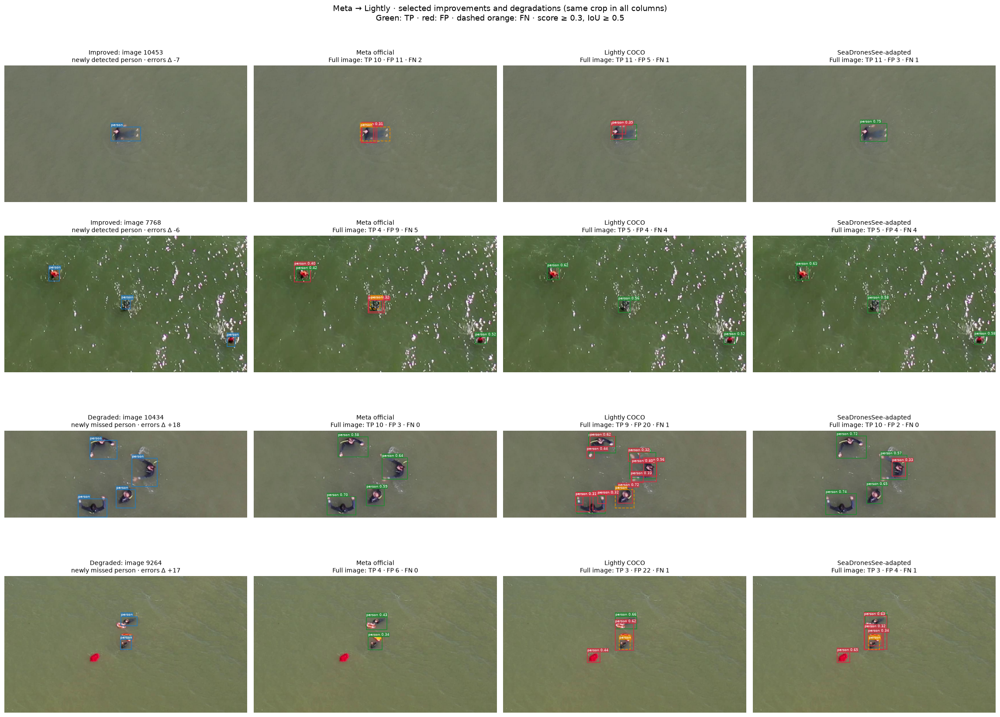

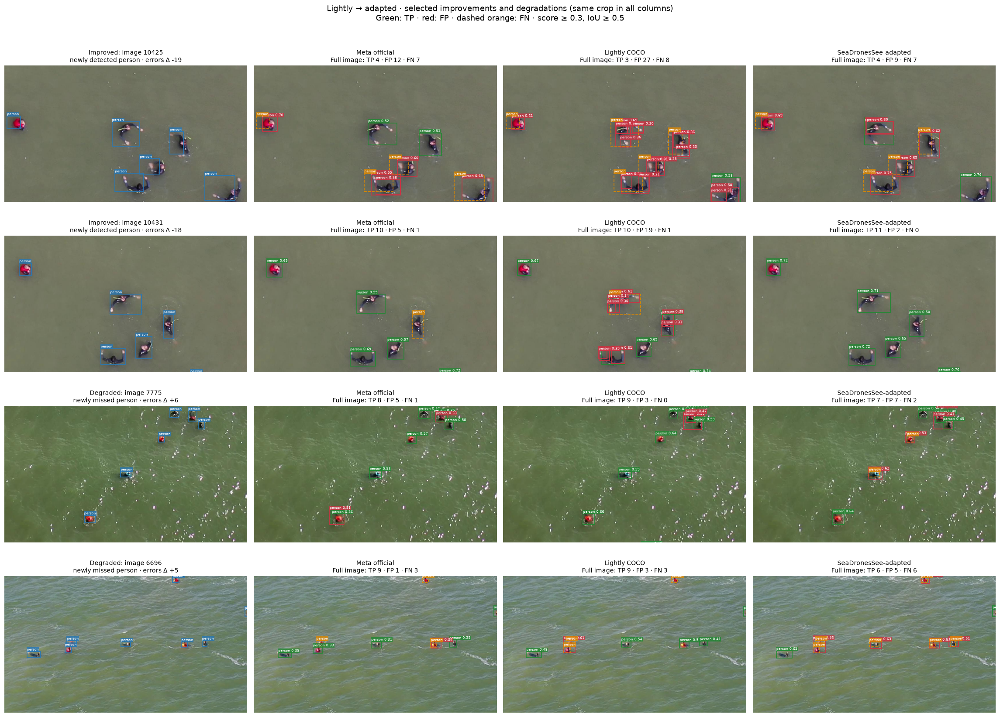

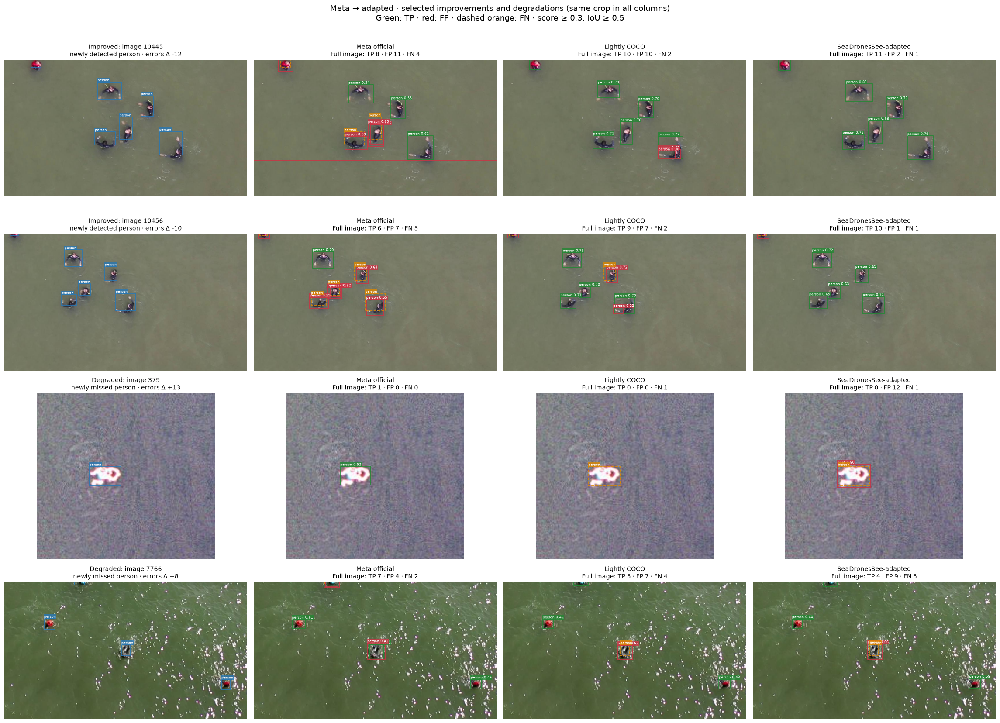

,transition,change,image_id,ground_truth,before_TP_FP_FN,after_TP_FP_FN,error_delta,focus_bbox,focus_reason
0,Meta → Lightly,Improved,10453,12,10/11/2,11/5/1,-7,"[1008, 1530, 103, 49]",newly detected person
1,Meta → Lightly,Improved,7768,9,4/9/5,5/4/4,-6,"[2329, 1825, 31, 34]",newly detected person
2,Meta → Lightly,Degraded,10434,10,10/3/0,9/20/1,18,"[2845, 2062, 66, 64]",newly missed person
3,Meta → Lightly,Degraded,9264,4,4/6/0,3/22/1,17,"[2486, 1419, 38, 34]",newly missed person
4,Lightly → adapted,Improved,10425,11,3/27/8,4/9/7,-19,"[3036, 1862, 96, 85]",newly detected person
5,Lightly → adapted,Improved,10431,11,10/19/1,11/2/0,-18,"[2663, 1709, 109, 69]",newly detected person
6,Lightly → adapted,Degraded,7775,9,9/3/0,7/7/2,6,"[2190, 1575, 36, 19]",newly missed person
7,Lightly → adapted,Degraded,6696,12,9/3/3,6/5/6,5,"[1446, 952, 34, 17]",newly missed person
8,Meta → adapted,Improved,10445,12,8/11/4,11/2/1,-12,"[2574, 1690, 45, 77]",newly detected person
9,Meta → adapted,Improved,10456,11,6/7/5,10/1/1,-10,"[2441, 1445, 70, 61]",newly detected person


In [49]:
selected_examples = []
used_images = set()
transitions = [(META_LABEL, BASELINE_LABEL, "Meta → Lightly"),
               (BASELINE_LABEL, ADAPTED_LABEL, "Lightly → adapted"),
               (META_LABEL, ADAPTED_LABEL, "Meta → adapted")]
for before, after, transition in transitions:
    before_errors = image_errors[f"{before} errors"]
    after_errors = image_errors[f"{after} errors"]
    delta = after_errors - before_errors
    selected = []
    for direction, change in ((-1, "Improved"), (1, "Degraded")):
        candidates = image_errors.loc[(delta * direction > 0) & (image_errors["ground_truth"] > 0)].copy()
        candidates["error_delta"] = delta.loc[candidates.index]
        candidates["magnitude"] = candidates["error_delta"].abs()
        tp_change = image_errors[f"{after} TP"] - image_errors[f"{before} TP"]
        candidates["target_change"] = (tp_change.loc[candidates.index] * -direction) > 0
        # Prefer readable scenes; fall back to crowded scenes only if needed.
        max_predictions = pd.concat([image_errors[f"{name} TP"] + image_errors[f"{name} FP"]
                                     for name in model_results], axis=1).max(axis=1)
        candidates["readable"] = (candidates["ground_truth"] <= 12) & (max_predictions.loc[candidates.index] <= 30)
        candidates = candidates.sort_values(["readable", "target_change", "magnitude"], ascending=False)
        chosen = [image_id for image_id in candidates.index if image_id not in used_images][:EXAMPLES_PER_CHANGE]
        if not chosen:
            print(f"No unused {change.lower()} examples found for {transition} at these thresholds.")
        for image_id in chosen:
            used_images.add(image_id)
            before_match, after_match = image_matches[before][image_id], image_matches[after][image_id]
            before_missed = {ann["id"] for ann in before_match["fn"]}
            after_missed = {ann["id"] for ann in after_match["fn"]}
            changed_targets = ([ann for ann in before_match["fn"] if ann["id"] not in after_missed]
                               if change == "Improved" else
                               [ann for ann in after_match["fn"] if ann["id"] not in before_missed])
            if changed_targets:
                focus = max(changed_targets, key=lambda ann: ann["bbox"][2] * ann["bbox"][3])
                focus_reason = ("newly detected " if change == "Improved" else "newly missed ") + SHARED_NAMES[focus["category_id"]]
            else:
                source_fp = before_match["fp"] if change == "Improved" else after_match["fp"]
                other_fp = after_match["fp"] if change == "Improved" else before_match["fp"]
                changed_fp = []
                for prediction in source_fp:
                    overlaps = box_iou(prediction["bbox"], [other["bbox"] for other in other_fp
                                                          if other["category_id"] == prediction["category_id"]])
                    if not len(overlaps) or overlaps.max() < EXAMPLE_IOU:
                        changed_fp.append(prediction)
                focus = max(changed_fp or source_fp, key=lambda prediction: prediction["score"])
                focus_reason = ("removed FP " if change == "Improved" else "new FP ") + SHARED_NAMES[focus["category_id"]]
            record = {"transition": transition, "change": change, "image_id": int(image_id),
                      "ground_truth": len(annotations_by_image[image_id]),
                      "before_TP_FP_FN": "/".join(str(len(before_match[key])) for key in ("tp", "fp", "fn")),
                      "after_TP_FP_FN": "/".join(str(len(after_match[key])) for key in ("tp", "fp", "fn")),
                      "error_delta": int(delta.loc[image_id]), "focus_bbox": focus["bbox"], "focus_reason": focus_reason}
            selected_examples.append(record)
            selected.append(record)
    if not selected:
        continue
    fig, axes = plt.subplots(len(selected), 4, figsize=(23, 4.3 * len(selected)), squeeze=False)
    for row, record in enumerate(selected):
        image_id = record["image_id"]
        with Image.open(VAL_IMAGES / val_gt.imgs[image_id]["file_name"]) as image:
            for ax in axes[row]:
                ax.imshow(image.convert("RGB"))
                ax.axis("off")
            width, height = image.size
        x, y, box_width, box_height = record["focus_bbox"]
        crop_width, crop_height = max(box_width * 5, width * 0.22), max(box_height * 5, height * 0.22)
        center_x, center_y = x + box_width / 2, y + box_height / 2
        left, right = max(0, center_x - crop_width / 2), min(width, center_x + crop_width / 2)
        top, bottom = max(0, center_y - crop_height / 2), min(height, center_y + crop_height / 2)
        for ax in axes[row]:
            ax.set_xlim(left, right)
            ax.set_ylim(bottom, top)
        axes[row, 0].set_title(f'{record["change"]}: image {image_id}\n{record["focus_reason"]} · errors Δ {record["error_delta"]:+d}', fontsize=10)
        for ann in annotations_by_image[image_id]:
            draw_box(axes[row, 0], ann["bbox"], SHARED_NAMES[ann["category_id"]], "#2878b5")
        for column, name in enumerate(model_results, start=1):
            match = image_matches[name][image_id]
            short_name = {META_LABEL: "Meta official", BASELINE_LABEL: "Lightly COCO", ADAPTED_LABEL: "SeaDronesSee-adapted"}[name]
            axes[row, column].set_title(f'{short_name}\nFull image: TP {len(match["tp"])} · FP {len(match["fp"])} · FN {len(match["fn"])}', fontsize=10)
            for key, color in (("tp", "#228833"), ("fp", "#cc3344"), ("fn", "#dd8800")):
                for box in match[key]:
                    text = SHARED_NAMES[box["category_id"]]
                    if key != "fn":
                        text += f' {box["score"]:.2f}'
                    draw_box(axes[row, column], box["bbox"], text, color, dashed=(key == "fn"))
    fig.suptitle(f"{transition} · selected improvements and degradations (same crop in all columns)\nGreen: TP · red: FP · dashed orange: FN · score ≥ {DISPLAY_THRESHOLD:g}, IoU ≥ {EXAMPLE_IOU:g}", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    slug = transition.replace(" → ", "_to_").replace(" ", "_").lower()
    fig.savefig(EVAL_DIR / f"examples_{slug}.png", dpi=140)
    plt.show()
selected_examples_table = pd.DataFrame(selected_examples)
selected_examples_table.to_csv(EVAL_DIR / "selected_change_examples.csv", index=False)
display(selected_examples_table)


## Adapted detector: native SeaDronesSee classes

These five-class metrics are separate from the three-way shared person/boat comparison.

,Adapted native metrics
AP,0.3512
AP50,0.5918
AP75,0.3687
AP_small,0.1674
AP_medium,0.3770
AP_large,0.6278
AR@1,0.2895
AR@10,0.4780
AR@100,0.5201
AR_small,0.3573


,Adapted native AP
swimmer,0.2827
boat,0.6217
jetski,0.5384
life_saving_appliances,0.0098
buoy,0.3032


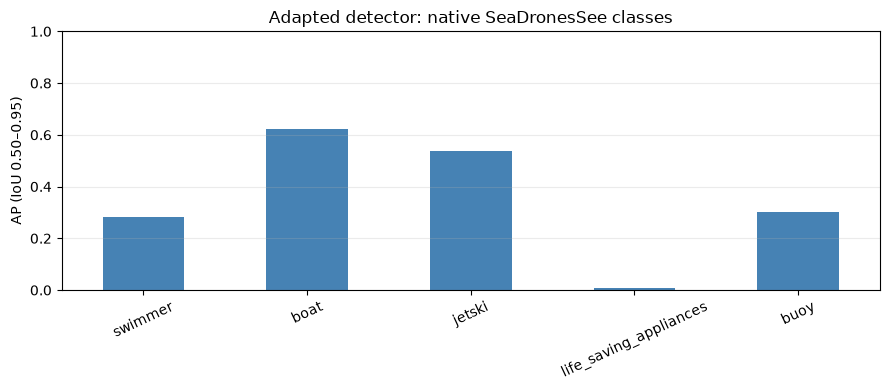

In [46]:
display(adapted_native_result["metrics"].to_frame("Adapted native metrics").round(4))
display(adapted_native_result["per_class"].to_frame("Adapted native AP").round(4))
fig, ax = plt.subplots(figsize=(9, 4))
adapted_native_result["per_class"].plot.bar(ax=ax, color="steelblue", rot=25)
ax.set(ylim=(0, 1), ylabel="AP (IoU 0.50–0.95)", title="Adapted detector: native SeaDronesSee classes")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(EVAL_DIR / "adapted_native_class_ap.png", dpi=160)
plt.show()

In [50]:
report = {
    "comparison": "Meta official vs Lightly COCO-pretrained vs SeaDronesSee-adapted",
    "models": {
        META_LABEL: {"architecture": "Meta ViT-7B/16 + official COCO detector", "precision": "BF16",
                     "backbone_weights": str(BACKBONE_WEIGHTS), "head_weights": str(DETECTOR_WEIGHTS)},
        BASELINE_LABEL: {"checkpoint": MODEL_NAME, "precision": "FP32"},
        ADAPTED_LABEL: {"starting_checkpoint": MODEL_NAME, "checkpoint": str(CHECKPOINT), "evaluation_precision": "FP32"},
    },
    "quantization": None, "evaluation_split": "validation", "scope": SCOPE,
    "shared_classes": SHARED_NAMES, "image_ids": eval_ids, "image_size": IMAGE_SIZE,
    "evaluation_threshold": EVAL_THRESHOLD, "display_threshold": DISPLAY_THRESHOLD,
    "example_iou": EXAMPLE_IOU, "example_selection": "Ranked changes in class-aware FP + FN; readable scenes and genuine TP gains/losses preferred",
    "meta_batch_size": META_BATCH_SIZE,
    "training": {"steps": TRAIN_STEPS, "microbatch": BATCH_SIZE, "accumulation": GRADIENT_ACCUMULATION,
                 "effective_batch": BATCH_SIZE * GRADIENT_ACCUMULATION, "workers": NUM_WORKERS,
                 "precision": TRAIN_PRECISION, "seed": SEED, "local_original_image_staging": STAGE_TRAIN_IMAGES},
    "training_profile": training_profile, "throughput_benchmarks": benchmark_rows,
    "native_to_shared": native_to_shared, "ignored_ids": ignored_ids,
    "train_annotations": str(TRAIN_JSON), "val_annotations": str(VAL_JSON),
    "checkpoint_selection": "best validation performance during training",
    "interpretation": "Meta vs Lightly changes architecture, size, and precision; Lightly vs adapted changes training and output class head. Shared person denotes annotated swimmers; unannotated people on boats can count as false positives.",
    "shared_AP": {name: float(result["metrics"]["AP"]) for name, result in model_results.items()},
}
(EVAL_DIR / "report.json").write_text(json.dumps(report, indent=2))
print("Comparison report:", EVAL_DIR / "report.json")
print("Persistent adapted checkpoint:", CHECKPOINT)
print("All three models evaluated on", len(eval_ids), "identical validation images.")


Comparison report: /home/paulpaul/runs/dinov3_vits16_comparison_001/three_way_full_validation/report.json
Persistent adapted checkpoint: /home/paulpaul/runs/dinov3_vits16_comparison_001/adapted_h100/exported_best.pt
All three models evaluated on 1547 identical validation images.
